# Inklight + Docling structure on Indra's OCR — a live showcase

Everything below is computed when the notebook runs, on this machine, with the real components:

* **Indra** reads the text (the only OCR).
* **Docling** finds layout, reading order and tables (Heron layout model, TableFormer) **on Indra's lines** — no second OCR.
* **Inklight** indexes, answers and cites.

The documents are **synthetic**: fictional registration cards (Arabic, English, mixed) written by
`bench/structure/make_synthetic.py`, saved as scans so Indra must OCR them. No private data.

Sections: 1 setup · 2 Indra OCR · 3 Docling on Indra's lines (and proof there is no second OCR) · 4 the tables ·
5 answers before/after · 6 honesty about OCR errors · 7 speed · 8 exports · 9 after the agent-run evaluation
(form labels, several candidates, the documents you pass, turned pages) · 10 the measured state on real documents.

In [1]:
import os, sys, time, json, platform, subprocess, tempfile, warnings, contextlib, io
os.environ["TQDM_DISABLE"] = "1"                 # no download/loading progress bars in the output
warnings.filterwarnings("ignore")
from pathlib import Path
from importlib.metadata import version

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "examples" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "bench" / "structure"))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pymupdf

pd.set_option("display.max_colwidth", 90)
OUT = ROOT / "examples" / "showcase_out"
OUT.mkdir(parents=True, exist_ok=True)
# INDRA_MODEL_DIR: a folder with the Indra models pinned for the measurements in docs/STRUCTURE.md (the outputs
# below were made with them); unset, Indra's default download is used.
INDRA_MODELS = os.environ.get("INDRA_MODEL_DIR") or None

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
pd.Series({
    "inklight commit": commit,
    "python": platform.python_version(),
    "indra-ocr": version("indra-ocr"),
    "docling": version("docling"),
    "docling-core": version("docling-core"),
    "torch": version("torch"),
    "cpu cores": os.cpu_count(),
}, name="environment").to_frame()

,environment
inklight commit,0183a4c
python,3.13.9
indra-ocr,1.1.2
docling,2.142.1
docling-core,2.104.0
torch,2.14.1
cpu cores,16


## 1 · The documents
The generator writes each card twice: with a text layer, and as a scan (images only).

['regcard-ar-scan.pdf', 'regcard-ar.pdf', 'regcard-en-scan.pdf', 'regcard-en.pdf', 'regcard-mixed-scan.pdf', 'regcard-mixed.pdf']


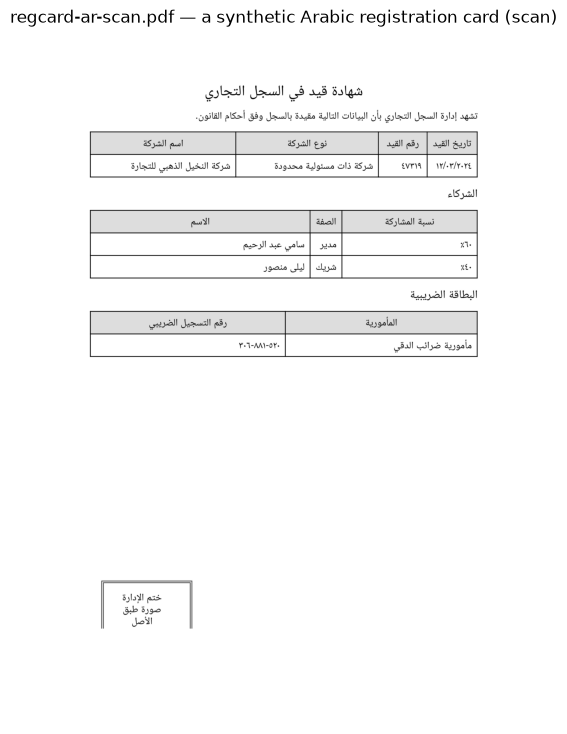

In [2]:
import make_synthetic
sys.argv = ["make_synthetic", str(OUT)]
with contextlib.redirect_stdout(io.StringIO()):
    make_synthetic.main()
print(sorted(p.name for p in OUT.glob("regcard-*.pdf")))

def show_page(pdf, title, boxes=(), scale=200 / 72, figsize=(9, 11), color="red"):
    """The page rendered in Inklight's pixel frame (Indra's 200 dpi), with boxes drawn on it."""
    page = pymupdf.open(pdf)[0]
    pix = page.get_pixmap(matrix=pymupdf.Matrix(scale, scale))
    import numpy as np
    arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(arr)
    for box in boxes:
        x0, y0, x1, y1 = box[:4]
        c = box[4] if len(box) > 4 else color
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=c, linewidth=1.6))
    ax.set_title(title); ax.axis("off"); plt.show()

show_page(OUT / "regcard-ar-scan.pdf", "regcard-ar-scan.pdf — a synthetic Arabic registration card (scan)", figsize=(7, 9))

## 2 · Indra reads the page
Indra's lines are what Inklight stores — text, box, confidence — and they are never changed afterwards.

In [3]:
from inklight.config import OCRSettings, StructureSettings
from inklight.ocr.indra import IndraEngine

indra = IndraEngine(OCRSettings(model_dir=INDRA_MODELS))
indra.read(OUT / "regcard-en-scan.pdf", max_pages=1)          # warm-up: Indra loads its models once
t = time.perf_counter()
content = indra.read(OUT / "regcard-ar-scan.pdf", max_pages=5)
print(f"Indra OCR: {time.perf_counter() - t:.2f} s for {len(content.pages)} page(s), {len(content.pages[0].lines)} lines")
page = content.pages[0]
pd.DataFrame([{"text": l.text, "confidence": l.conf, "box (pixels)": l.bbox} for l in page.lines])

Indra OCR: 0.18 s for 1 page(s), 28 lines


,text,confidence,box (pixels)
0,شهادة قيد في السجل التجاري,0.9786,"(553.3, 179.6, 1100.4, 237.0)"
1,تشهد إدارة السجل التجاري بأن البيانات التالية مقيدة بالسجل وفق أحكام القانون.,0.9847,"(528.2, 265.7, 1486.4, 307.6)"
2,تاريخ القيد,0.8702,"(1323.7, 363.6, 1463.0, 401.9)"
3,رقم القيد,0.9337,"(1172.9, 363.1, 1326.0, 401.4)"
4,نوع الشركة,0.9712,"(835.7, 366.2, 973.3, 398.6)"
5,اسم الشركة,0.9313,"(351.7, 367.0, 488.9, 397.7)"
6,14/-V/8-18,0.8267,"(1333.8, 439.0, 1462.0, 470.5)"
7,EVY19,0.6198,"(1219.9, 440.8, 1297.3, 470.3)"
8,شركة ذات مسئولية محدودة,0.9904,"(790.0, 441.4, 1133.2, 473.7)"
9,شركة النخيل الذهبي للتجارة,0.9244,"(305.3, 440.7, 649.5, 476.4)"


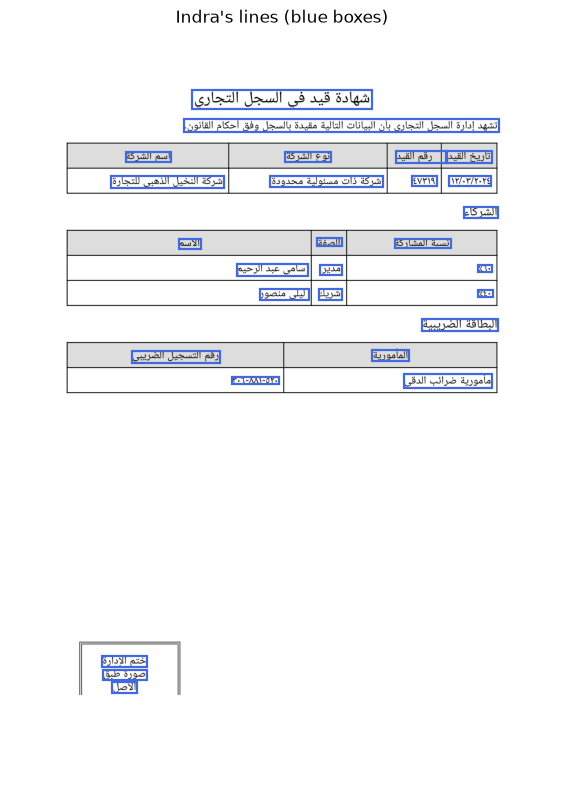

In [4]:
show_page(OUT / "regcard-ar-scan.pdf", "Indra's lines (blue boxes)", [(*l.bbox, "royalblue") for l in page.lines], figsize=(8, 10))

## 3 · Docling on Indra's lines

Inklight registers an OCR engine with Docling that does **no recognition**: it hands Docling Indra's stored lines as
its text cells (`OcrMode.FULL_PAGE`). Docling's own layout model, reading order and TableFormer then run unchanged.
Each run records what it did.

In [5]:
from inklight.structure import structure_document, load_document

settings = StructureSettings(engine="docling")      # the defaults: accurate tables, ONNX layout, every core
t = time.perf_counter()
done = structure_document(OUT / "regcard-ar-scan.pdf", content, settings)
first = time.perf_counter() - t
t = time.perf_counter()
done = structure_document(OUT / "regcard-ar-scan.pdf", content, settings)
again = time.perf_counter() - t
m = done.meta
print(f"first run (loads the models): {first:.1f} s   ·   next run (models loaded): {again:.2f} s")
pd.Series({
    "Indra lines with text and box": sum(1 for l in page.lines if l.text.strip() and l.bbox),
    "cells handed to Docling": m["cells_delivered"],
    "words in Docling's output Indra never read": m["foreign_tokens"],
    "Indra lines no Docling item holds": m["orphan_lines"],
    "tables found": m["tables"],
    "layout": m["components"]["layout"],
    "tables model": m["components"]["tables"],
    "OCR inside Docling": m["components"]["ocr"],
}, name="this run").to_frame()

first run (loads the models): 10.3 s   ·   next run (models loaded): 1.39 s


,this run
Indra lines with text and box,28
cells handed to Docling,28
words in Docling's output Indra never read,0
Indra lines no Docling item holds,0
tables found,3
layout,Heron (onnx)
tables model,"TableFormer (accurate), cell matching on the given text cells"
OCR inside Docling,none in Docling: Indra's stored lines are its text cells (OcrMode.FULL_PAGE)


### Proof there is no second OCR

Control experiment: replace **every** Indra line with a marker word (`MARK0`, `MARK1`, …) and run Docling again on the
same page image. If Docling read the page itself, real words would appear. Only the markers come back.

In [6]:
from inklight.schemas import TextLine
marked = content.model_copy(update={"pages": tuple(
    p.model_copy(update={"lines": tuple(TextLine(text=f"MARK{i}", bbox=l.bbox) for i, l in enumerate(p.lines))})
    for p in content.pages)})
control = structure_document(OUT / "regcard-ar-scan.pdf", marked, settings)
words = sorted({w.strip("|:") for p in control.content.pages for b in p.blocks for w in b.text.split()} - {""})
print("words in Docling's output:", words[:12], "…")
print("anything that is not a marker?", [w for w in words if not w.startswith("MARK")])

words in Docling's output: ['MARK0', 'MARK1', 'MARK10', 'MARK11', 'MARK12', 'MARK13', 'MARK14', 'MARK15', 'MARK16', 'MARK17', 'MARK18', 'MARK19'] …
anything that is not a marker? []


## 4 · What Docling recovered: blocks in reading order, and the tables cell by cell

In [7]:
blocks = done.content.pages[0].blocks
pd.DataFrame([{"label": b.label, "docling ref": b.ref, "text (tables: header: value)": b.text} for b in blocks])

,label,docling ref,text (tables: header: value)
0,Section-Header,#/texts/0,شهادة قيد في السجل التجاري
1,Text,#/texts/1,تشهد إدارة السجل التجاري بأن البيانات التالية مقيدة بالسجل وفق أحكام القانون.
2,Table,#/tables/0,اسم الشركة: شركة النخيل الذهبي للتجارة | نوع الشركة: شركة ذات مسئولية محدودة | رقم الق...
3,Text,#/texts/2,الشركاء
4,Table,#/tables/1,الاسم: سامي عبد الرحيم | الصفة: مدیر | نسبة المشاركة: 27.\nالاسم: ليلى منصور | الصفة: ...
5,Text,#/texts/3,البطاقة الضريبية
6,Table,#/tables/2,رقم التسجيل الضريبي: 8.7-11-08. | المأمورية: مأمورية ضرائب الدقي
7,Text,#/texts/4,ختم الإدارة صورة طبق الأصل


In [8]:
from inklight.structure.adapter import table_grid
document = load_document(done.document_json)
for t in document.tables:
    g = table_grid(t, document)
    df = pd.DataFrame(g.rows)
    df.index = ["header" if r in g.header_rows else f"row {r}" for r in range(len(g.rows))]
    print(t.self_ref, "— header rows flagged by TableFormer:", sorted(g.header_rows))
    display(df)

#/tables/0 — header rows flagged by TableFormer: []


,0,1,2,3
row 0,اسم الشركة,نوع الشركة,رقم القيد,تاريخ القيد
row 1,شركة النخيل الذهبي للتجارة,شركة ذات مسئولية محدودة,EVY19,14/-V/8-18


#/tables/1 — header rows flagged by TableFormer: [0]


,0,1,2
header,الاسم,الصفة,نسبة المشاركة
row 1,سامي عبد الرحيم,مدیر,27.
row 2,ليلى منصور,شريك,72.


#/tables/2 — header rows flagged by TableFormer: []


,0,1
row 0,رقم التسجيل الضريبي,المأمورية
row 1,8.7-11-08.,مأمورية ضرائب الدقي


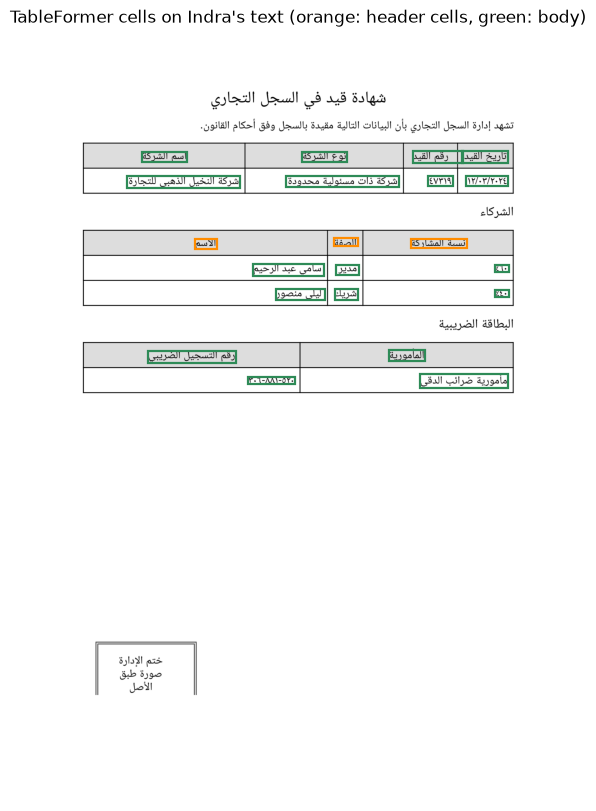

In [9]:
from inklight.structure.adapter import to_inklight
cell_boxes = []
for t in document.tables:
    size = document.pages[t.prov[0].page_no].size
    for c in t.data.table_cells:
        b = to_inklight(c.bbox, size, page)
        if b: cell_boxes.append((*b, "darkorange" if c.column_header else "seagreen"))
show_page(OUT / "regcard-ar-scan.pdf", "TableFormer cells on Indra's text (orange: header cells, green: body)", cell_boxes, figsize=(8, 10))

## 5 · Answers before and after

Two fresh libraries read the **same** scans with the **same** Indra OCR, in rules mode (no language model):

* **without structure** — Inklight as before (`[structure] engine = "none"`),
* **with structure** — Docling's tables on Indra's lines (`engine = "docling"`).

The questions name a field printed as a column heading over its value, or a person in a table of several people.

In [10]:
from inklight import DocumentAgent
from inklight.config import ModelSettings, Settings

FILES = ["regcard-ar-scan.pdf", "regcard-en-scan.pdf", "regcard-mixed-scan.pdf"]
QUESTIONS = [
    ("regcard-ar-scan.pdf", "ما اسم الشركة؟", "شركة النخيل الذهبي للتجارة"),
    ("regcard-ar-scan.pdf", "ما نوع الشركة؟", "شركة ذات مسئولية محدودة"),
    ("regcard-ar-scan.pdf", "من المدير؟", "سامي عبد الرحيم"),
    ("regcard-ar-scan.pdf", "ما المأمورية؟", "مأمورية ضرائب الدقي"),
    ("regcard-en-scan.pdf", "What is the company name?", "Golden Palm Trading Co"),
    ("regcard-en-scan.pdf", "What is the company type?", "Limited liability company"),
    ("regcard-en-scan.pdf", "What is the registration number?", "47319"),
    ("regcard-en-scan.pdf", "Who is the manager?", "Samuel Reed"),
    ("regcard-en-scan.pdf", "What is Laila Mansour's share?", "40%"),
    ("regcard-mixed-scan.pdf", "What is the registration number?", "47319"),
    ("regcard-mixed-scan.pdf", "ما رقم القيد؟", "47319"),
]

def ask_all(engine):
    home = Path(tempfile.mkdtemp(prefix=f"showcase-{engine}-"))
    s = Settings(home=home, ocr=OCRSettings(model_dir=INDRA_MODELS),
                 models=ModelSettings(brain="rules", allow_download=False), structure={"engine": engine})
    out = []
    with DocumentAgent(s) as agent:
        t = time.perf_counter(); agent.add([OUT / f for f in FILES]); ingest = time.perf_counter() - t
        ids = {d.name: d.id for d in agent.library.documents()}
        for doc, q, expect in QUESTIONS:
            r = agent.ask(q, doc_ids=[ids[doc]], save=False)
            head = r.answer.split("\n\nEvidence:")[0].strip()
            flagged = any(w.startswith("Low confidence") for w in r.warnings)
            declined = head.startswith(("I couldn't find", "I could not find"))
            right = expect.lower() in head.lower()
            listed = " values under " in head  # several rows listed, none chosen
            verdict = ("declined" if declined else "listed, not chosen" if listed
                       else ("correct" if right else "WRONG") + (" (flagged)" if flagged else ""))
            src = r.sources[0] if r.sources else None
            out.append({"question": q, "answer": head[:60], "verdict": verdict,
                        "cited": f"p.{src.page} {tuple(round(v) for v in src.bbox)}" if src and src.bbox else "—"})
    return pd.DataFrame(out), ingest, ids, s

before, t_before, _, _ = ask_all("none")
after, t_after, ids_after, s_after = ask_all("docling")
print(f"ingest of {len(FILES)} scans: without structure {t_before:.1f} s · with structure {t_after:.1f} s (includes loading Docling)")
pd.concat({"without structure": before.drop(columns=["question"]), "with structure": after.drop(columns=["question"])},
          axis=1).set_index(before["question"])

ingest of 3 scans: without structure 1.2 s · with structure 4.7 s (includes loading Docling)


without structure  \
                                                                                        answer   
question                                                                                         
ما اسم الشركة؟                                                      شركة النخيل الذهبي للتجارة   
ما نوع الشركة؟                                                         شركة ذات مسئولية محدودة   
من المدير؟                                                                                شريك   
ما المأمورية؟                     I couldn't find supporting evidence for the الماموريه in the   
What is the company name?         I couldn't find supporting evidence for the company in the p   
What is the company type?         I couldn't find supporting evidence for the company in the p   
What is the registration number?                                                   520-881-306   
Who is the manager?                                                                        60%   
What is Laila Mansour's share?    I couldn't find supporting evidence for the share in the pro   
What is the registration number?                                                         47319   
ما رقم القيد؟                                               25,11 25 Limited liability company   

                                                                               \
                                          verdict                       cited   
question                                                                        
ما اسم الشركة؟                            correct    p.1 (305, 367, 650, 476)   
ما نوع الشركة؟                            correct   p.1 (790, 366, 1133, 474)   
من المدير؟                                  WRONG   p.1 (938, 712, 1010, 818)   
ما المأمورية؟                            declined                           —   
What is the company name?                declined                           —   
What is the company type?                declined                           —   
What is the registration number?  WRONG (flagged)  p.1 (188, 1089, 740, 1191)   
Who is the manager?                         WRONG  p.1 (1197, 826, 1439, 857)   
What is Laila Mansour's share?           declined                           —   
What is the registration number?          correct    p.1 (192, 442, 800, 476)   
ما رقم القيد؟                     WRONG (flagged)   p.1 (520, 444, 1070, 553)   

                                              with structure           \
                                                      answer  verdict   
question                                                                
ما اسم الشركة؟                    شركة النخيل الذهبي للتجارة  correct   
ما نوع الشركة؟                       شركة ذات مسئولية محدودة  correct   
من المدير؟                                   سامي عبد الرحيم  correct   
ما المأمورية؟                            مأمورية ضرائب الدقي  correct   
What is the company name?            Golden Palm Trading Co.  correct   
What is the company type?          Limited liability company  correct   
What is the registration number?                       47319  correct   
Who is the manager?                              Samuel Reed  correct   
What is Laila Mansour's share?                           40%  correct   
What is the registration number?                       47319  correct   
ما رقم القيد؟                                          47319  correct   

                                                                
                                                         cited  
question                                                        
ما اسم الشركة؟                        p.1 (305, 441, 650, 476)  
ما نوع الشركة؟                       p.1 (790, 441, 1133, 474)  
من المدير؟                            p.1 (689, 707, 905, 742)  
ما المأمورية؟                     p.1 (1195, 1042, 1464, 1084)  
What is the company name?             p.1 (192, 520, 512, 586)  
What is the company type? 

In [11]:
summary = pd.DataFrame({
    "without structure": before["verdict"].str.replace(r" \(flagged\)", "", regex=True).value_counts(),
    "with structure": after["verdict"].str.replace(r" \(flagged\)", "", regex=True).value_counts(),
}).fillna(0).astype(int)
summary

,without structure,with structure
verdict,,
WRONG,4,0
correct,3,11
declined,4,0


These are **11 questions chosen for three synthetic cards** made for this showcase, whose fields are printed
as column headings over their values. 11 of 11 with structure shows that the table path works on that layout; it
is not a measure of accuracy on real documents. Section 10 has the measured state on real scans.

شركة النخيل الذهبي للتجارة

Evidence: “اسم الشركة: شركة النخيل الذهبي للتجارة” (table, page 1)


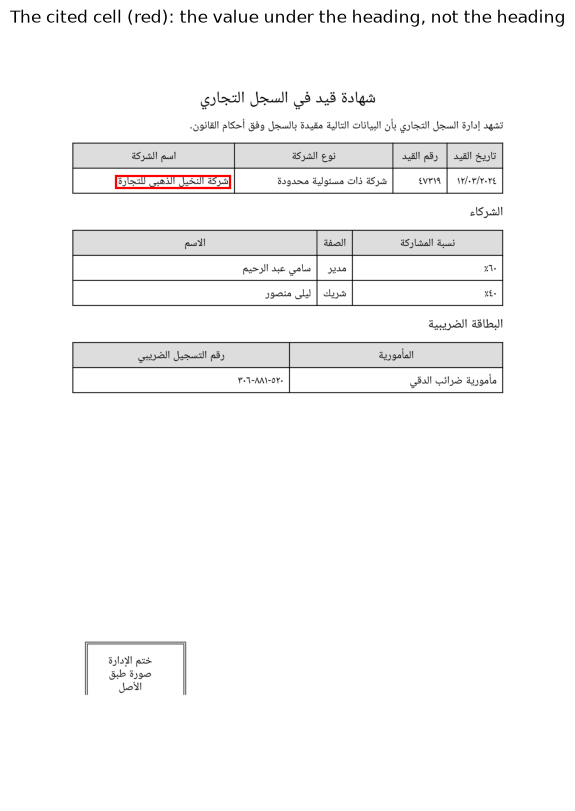

In [12]:
# Where the answer to "ما اسم الشركة؟" came from: the cited cell, in the page's pixel frame
with DocumentAgent(s_after) as agent:
    r = agent.ask("ما اسم الشركة؟", doc_ids=[ids_after["regcard-ar-scan.pdf"]], save=False)
print(r.answer)
show_page(OUT / "regcard-ar-scan.pdf", "The cited cell (red): the value under the heading, not the heading",
          [(*r.sources[0].bbox, "red")], figsize=(8, 10))

## 6 · Honest about OCR errors

Indra misreads some Arabic-Indic digits on these scans. Structure cannot fix a misread value — but the answer says
it is unsure, because Indra read that cell with low confidence.

In [13]:
with DocumentAgent(s_after) as agent:
    for q in ["ما رقم القيد؟", "ما تاريخ القيد؟"]:
        r = agent.ask(q, doc_ids=[ids_after["regcard-ar-scan.pdf"]], save=False)
        print(q, "→", r.answer.split("\n\n")[0][:70], "| confidence", r.confidence)
        for w in r.warnings: print("   ⚠", w)
        print()
print("Printed on the card: رقم القيد ٤٧٣١٩ · تاريخ القيد ١٢/٠٣/٢٠٢٤")

ما رقم القيد؟ → EVY19 | confidence 0.25
   ⚠ Low confidence: the OCR read this cell with low confidence (0.62); check it against the page.

ما تاريخ القيد؟ → I couldn't find supporting evidence for a value of “تاريخ القيد” in th | confidence 0.4

Printed on the card: رقم القيد ٤٧٣١٩ · تاريخ القيد ١٢/٠٣/٢٠٢٤


## 7 · Speed: where the time goes, and what the options cost

Docling's own per-stage profiler, on a 9-page scan (the synthetic cards repeated, 21 tables), with Indra's OCR
stored and replayed. Each configuration builds its own converter; the second conversion (models warm) is timed.

In [14]:
from docling.datamodel.settings import settings as docling_settings
from inklight.structure import docling_run, indra_ocr

src = pymupdf.open()
for _ in range(3):
    for f in ["regcard-ar-scan.pdf", "regcard-en-scan.pdf", "regcard-mixed-scan.pdf"]:
        src.insert_pdf(pymupdf.open(OUT / f))
nine = OUT / "nine-pages-scan.pdf"; src.save(nine)
t = time.perf_counter(); nine_content = indra.read(nine, max_pages=20); ocr_s = time.perf_counter() - t
print(f"Indra OCR of the 9 pages: {ocr_s:.1f} s")

docling_settings.debug.profile_pipeline_timings = True
def profile(**kw):
    st = StructureSettings(engine="docling", **kw)
    conv, _ = docling_run._converter(st)
    for attempt in range(2):
        with tempfile.TemporaryDirectory() as work:
            pdf = docling_run._images_only(nine, [p.number for p in nine_content.pages], Path(work), None)
            t = time.perf_counter()
            with indra_ocr.lines_for(pdf, list(nine_content.pages)):
                res = conv.convert(pdf)
            took = time.perf_counter() - t
    stages = {k: sum(v.times) for k, v in res.timings.items()}
    return {"total (s)": round(took, 2), "layout stage (s)": round(stages["layout"], 2),
            "table stage (s)": round(stages["table_structure"], 2), "tables": len(res.document.tables)}

configs = {
    "before: torch layout, 4 threads": dict(layout_runtime="torch", threads=4),
    "now (default): ONNX layout, all cores": dict(),
    "option: + fast tables": dict(table_mode="fast"),
    "option: + TableFormer v2": dict(table_model="tableformer_v2"),
}
speed = pd.DataFrame({name: profile(**kw) for name, kw in configs.items()}).T
speed

Indra OCR of the 9 pages: 1.8 s


,total (s),layout stage (s),table stage (s),tables
"before: torch layout, 4 threads",17.76,5.92,15.86,21.0
"now (default): ONNX layout, all cores",8.50,2.02,8.10,21.0
option: + fast tables,6.15,2.00,5.69,21.0
option: + TableFormer v2,7.26,2.33,6.83,21.0


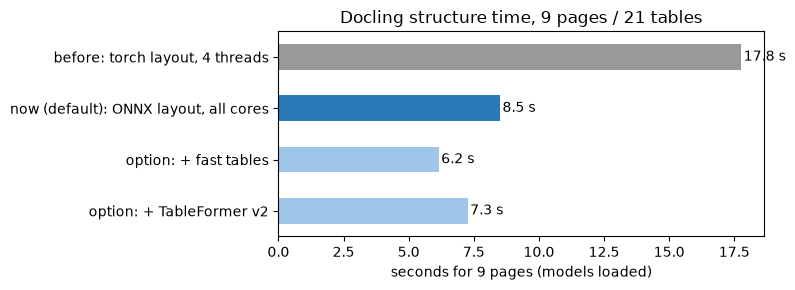

The 'fast' and 'v2' options are off by default: in the comparison (docs/STRUCTURE.md) fast tables lost one Arabic
answer and TableFormer v2 lost two low-confidence warnings. TableFormer is most of what is left.


In [15]:
ax = speed["total (s)"].plot.barh(figsize=(8, 3), color=["#999999", "#2a7ab9", "#9fc5e8", "#9fc5e8"])
ax.invert_yaxis(); ax.set_xlabel("seconds for 9 pages (models loaded)")
ax.set_title("Docling structure time, 9 pages / 21 tables")
for i, v in enumerate(speed["total (s)"]): ax.text(v + 0.1, i, f"{v:.1f} s", va="center")
plt.tight_layout(); plt.show()
print("The 'fast' and 'v2' options are off by default: in the comparison (docs/STRUCTURE.md) fast tables lost one Arabic")
print("answer and TableFormer v2 lost two low-confidence warnings. TableFormer is most of what is left.")

## 8 · Exports — Docling's own exporters on the stored structure

In [16]:
with DocumentAgent(s_after) as agent:
    meta, doc = agent.library.structure(ids_after["regcard-en-scan.pdf"])
markdown = doc.export_to_markdown(traverse_pictures=True)
print(markdown[:1200])
print("…\nJSON export:", len(json.dumps(doc.export_to_dict())), "characters ·",
      "CLI: inklight structure regcard-en-scan.pdf --format md|json|html|meta")

## Certificate of Commercial Registration

The Commercial Registry certifies that the following particulars are entered in the register.

| Company name            | Company type              |   Registration number | Registration date   |
|-------------------------|---------------------------|-----------------------|---------------------|
| Golden Palm Trading Co. | Limited liability company |                 47319 | 12/03/2024          |

## Partners

| Name          | Role    | Share   |
|---------------|---------|---------|
| Samuel Reed   | Manager | 60%     |
| Laila Mansour | Partner | 40%     |

## Tax card

| Tax registration number   | Tax office       |
|---------------------------|------------------|
| 520-881-306               | Dokki Tax Office |

Registry stamp Certified true
…
JSON export: 20165 characters · CLI: inklight structure regcard-en-scan.pdf --format md|json|html|meta


## 9 · After the agent-run evaluation: what changed

An agent-run evaluation on real, mostly scanned Egyptian business documents (`docs/AGENT_EVALUATION.md`) found
three answer defects and a gap in the structure step. Each fix is shown here, live. Two kinds of input:

* **the real pipeline** (Indra, Docling, Inklight) on synthetic PDFs, and
* where a form's exact geometry matters, **fixed OCR lines** standing in for Indra (as the unit tests do), copying
  the layout of the page that failed, with invented text. Those cells say so.

No private document, name or number is used.

In [17]:
from inklight.library import Library
from inklight.schemas import Block, DocumentContent, PageContent
import base64

PNG = base64.b64decode('iVBORw0KGgoAAAANSUhEUgAAAAEAAAABCAIAAACQd1PeAAAADElEQVR4nGP4//8/AAX+Av4N70a4AAAAAElFTkSuQmCC')

class FixedLines:
    """Stands in for Indra: fixed OCR lines (box, text), one list per page."""
    name = 'fixed-lines'
    def __init__(self, pages, size=(1000.0, 800.0)):
        self.pages, self.size = pages, size
    def supports(self, kind):
        return kind in ('png', 'jpeg')
    def read(self, path, *, max_pages, password=None):
        out = []
        for n, raw in enumerate(self.pages[path.name][:max_pages], 1):
            lines = tuple(TextLine(text=t, bbox=tuple(map(float, b)), conf=0.95) for b, t in raw)
            blocks = tuple(Block(index=k, label='Text', text=x.text, bbox=x.bbox, conf=0.95) for k, x in enumerate(lines))
            out.append(PageContent(number=n, width=self.size[0], height=self.size[1], source='ocr', lines=lines,
                                   blocks=blocks, markdown='\n'.join(x.text for x in lines)))
        return DocumentContent(path=str(path), pages=tuple(out), total_pages=len(out), engine=self.name)

def fixed_library(pages, size=(1000.0, 800.0)):
    """A fresh library whose documents are the given fixed pages; returns (agent, ids)."""
    work = Path(tempfile.mkdtemp(prefix='showcase-lines-'))
    for k, name in enumerate(pages):
        (work / name).write_bytes(PNG + bytes(k + 1))
    s = Settings(home=work / 'home', models=ModelSettings(brain='rules', allow_download=False))
    agent = DocumentAgent(s, library=Library(s, engine=FixedLines(pages, size)))
    agent.add([work / n for n in pages])
    return agent, {d.name: d.id for d in agent.library.documents()}

def head(r):
    return r.answer.split('\n\nEvidence:')[0].strip()

### 9.1 · A form label is not a value

A commercial register prints its field names as a numbered stack in one header cell (`١- نوع الشركة`, then
`(ب) ٢- عنوان الشركة أو اسمها`, …) with the values in a data row further down. The evaluated build answered
"ما نوع الشركة؟" (company type?) with the *next field name*, as if it were the value, and no warning. Now, in
the cases reproduced here, a numbered field name is not returned as another field's value; if the value is not
beside or below the field, the answer declines **and says where the field is** so a person can read it. *(Fixed OCR lines, copying that page's
geometry; invented text.)*

In [18]:
REGISTER = [  # (x0, y0, x1, y1), text: right to left, the header column of a register
    ((1869, 244, 1976, 264), '١-الأسم التجارى'), ((1864, 271, 1999, 292), '(١) -السمة التجارية'),
    ((1874, 326, 1971, 347), '١- نوع الشركة'), ((1750, 356, 2003, 376), '(ب) ٢- عنوان الشركة أو اسمها او اسم'),
    ((1865, 382, 1976, 402), 'الجمعية التعاونية'), ((1856, 412, 1971, 431), '٣- السمة التجارية'),
    ((1837, 499, 1866, 520), '(٢)'), ((1700, 567, 2004, 590), 'النجمة الزرقاء للتوريدات'),
]
NUMBERED = [((100, 120, 330, 142), '1. Company name'), ((100, 150, 330, 172), '2. Company type'),
            ((100, 180, 330, 202), '3. Head office address'), ((100, 210, 600, 232), '4. Registration number: 31907')]
LOOKALIKE = [((100, 120, 300, 142), 'Company name:'), ((320, 120, 600, 142), 'Name Holdings'),
             ((100, 180, 300, 202), 'Registration'), ((100, 204, 300, 226), 'number:'), ((320, 204, 600, 226), '77881')]

rows = []
for pages, size, asks in [
    ({'register.png': [REGISTER]}, (2338.0, 1653.0), [('register.png', 'ما نوع الشركة؟'), ('register.png', 'ما اسم الشركة؟')]),
    ({'numbered.png': [NUMBERED]}, (1000.0, 800.0), [('numbered.png', 'What is the company type?'),
                                                     ('numbered.png', 'What is the registration number?')]),
    ({'lookalike.png': [LOOKALIKE]}, (1000.0, 800.0), [('lookalike.png', 'What is the company name?'),
                                                       ('lookalike.png', 'What is the registration number?')]),
]:
    agent, ids = fixed_library(pages, size)
    with agent:
        for doc, q in asks:
            r = agent.ask(q, doc_ids=[ids[doc]], save=False)
            rows.append({'page': doc, 'question': q, 'answer': head(r)[:150]})
pd.set_option('display.max_colwidth', 150)
pd.DataFrame(rows)

,page,question,answer
0,register.png,ما نوع الشركة؟,I couldn't find supporting evidence for a value of “نوع الشركة” in the processed text of this document: the field name “نوع الشركة” is printed on ...
1,register.png,ما اسم الشركة؟,I couldn't find supporting evidence for a value of “نوع الشركة” in the processed text of this document: the field name “نوع الشركة” is printed on ...
2,numbered.png,What is the company type?,I couldn't find supporting evidence for a value of “Company type” in the processed text of this document: the field name “Company type” is printed...
3,numbered.png,What is the registration number?,31907
4,lookalike.png,What is the company name?,Name Holdings
5,lookalike.png,What is the registration number?,77881


The register's questions now decline and point at page 1 instead of presenting another field name as the value.
One flaw remains and is visible above: for "ما اسم الشركة؟" (the company **name**) the decline names the
company **type** field, because the field that names the company also names its address, so the closest exact
field is the wrong one. A filled field in the same numbered list still answers, and values that look like their
labels ("Name Holdings") or labels wrapped over two lines ("Registration / number:") are kept. This makes the
failure **safe, not solved**: the value itself is still not read from the data row.

### 9.2 · Several candidates: listed, or the one you name

The evaluation's control: one PDF with two tables that have identical headings, "Supplier 1" Alpha Ltd and
"Supplier 2" Beta Ltd. With structure on, the evaluated build answered "What is the company name?" with
Alpha Ltd alone. Real pipeline, digital PDF, generated by `bench/agent_eval/make_controls.py`.

In [19]:
sys.path.insert(0, str(ROOT / 'bench' / 'agent_eval'))
import make_controls
sys.argv = ['make_controls', str(OUT)]
with contextlib.redirect_stdout(io.StringIO()):
    make_controls.main()
CONTROL = OUT / 'control-two-companies.pdf'
CONTROL_QUESTIONS = ['What is the company name?', 'What type of company is Beta Ltd?',
                     "What is Alpha Ltd's company type?", 'What is the name of the second supplier?']

def control_answers(engine):
    home = Path(tempfile.mkdtemp(prefix=f'showcase-control-{engine}-'))
    s = Settings(home=home, ocr=OCRSettings(model_dir=INDRA_MODELS),
                 models=ModelSettings(brain='rules', allow_download=False), structure={'engine': engine})
    with DocumentAgent(s) as agent:
        report = agent.add([CONTROL]); doc = report.documents[0].id
        return [head(agent.ask(q, doc_ids=[doc], save=False)).replace('\n', ' | ')[:140] for q in CONTROL_QUESTIONS]

pd.DataFrame({'question': CONTROL_QUESTIONS, 'structure off': control_answers('none'),
              'structure on (Docling)': control_answers('docling')})

,question,structure off,structure on (Docling)
0,What is the company name?,I couldn't find supporting evidence for the company in the processed text of this document.,"“Company name” has a different value in each of 2 tables: | - Alpha Ltd: table on control-two-companies.pdf, page 1 | - Beta Ltd: table on c"
1,What type of company is Beta Ltd?,I couldn't find supporting evidence for the company in the processed text of this document.,Limited company
2,What is Alpha Ltd's company type?,I couldn't find supporting evidence for the company in the processed text of this document.,Limited company
3,What is the name of the second supplier?,"“Supplier” is printed 2 times with different values: | - 1: under “he following companies were registered in the supplier list.”, page 1 | -","“Supplier” is printed 2 times with different values: | - 1: under “he following companies were registered in the supplier list.”, page 1 | -"


With structure on, the general question lists both companies with where each is, and a question naming one gets
that one. Two things are **not** fixed and are shown as they are: with structure off this digital page is still
answered "couldn't find", and "the second supplier" is a flagged non-answer (it lists "1" and "2").

The same rule applies across documents: one field in two documents is listed, not taken from the first. *(Fixed
OCR lines, invented names.)*

In [20]:
agent, ids = fixed_library({
    'card-one.png': [[((100, 100, 300, 120), 'Company name:'), ((320, 100, 600, 120), 'Cedar Logistics')]],
    'card-two.png': [[((100, 100, 300, 120), 'Company name:'), ((320, 100, 600, 120), 'Nile Foods')]],
})
with agent:
    r = agent.ask('What is the company name?', doc_ids=list(ids.values()), save=False)
print(r.answer); print(); [print('⚠', w) for w in r.warnings]

“Company name” has a different value in each of 2 documents:
- Cedar Logistics: card-one.png, page 1
- Nile Foods: card-two.png, page 1

⚠ Low confidence: “Company name” is printed in 2 documents with different values and the question does not say which document is meant; name it.


[None]

### 9.3 · The documents you pass are kept

Asked to compare a contract with a commercial register, the evaluated build read "contract" as a filter, dropped
the register, and failed: *Comparison needs at least two documents*. The documents a person passes are now kept
unless the request restricts them ("only the contracts", "العقود فقط"). Real pipeline: two digital PDFs, through
the Python API and through the command line.

In [21]:
def text_pdf(path, lines):
    d = pymupdf.open(); page = d.new_page()
    for k, line in enumerate(lines):
        page.insert_text((60, 80 + 22 * k), line, fontsize=11)
    d.save(path); return path

contract = text_pdf(OUT / 'contract.pdf', ['SERVICE AGREEMENT',
    'This contract is made on 3 March 2024 between Cedar Logistics and Nile Foods.',
    'The parties agree that this agreement is governed by the laws of Egypt.', 'Registration number: 760413'])
register = text_pdf(OUT / 'register.pdf', ['COMMERCIAL REGISTER EXTRACT', 'Registration number: 760413',
    'Valid until: 3 April 2027'])
home = Path(tempfile.mkdtemp(prefix='showcase-scope-'))
s_scope = Settings(home=home, models=ModelSettings(brain='rules', allow_download=False))
rows = []
with DocumentAgent(s_scope) as agent:
    for q in ['Compare the registration number in the contract with the commercial register.',
              'قارن بين رقم السجل في العقد ومستخرج السجل التجاري', 'Summarize only the contracts']:
        r = agent.ask(q, files=[contract, register], save=False)
        scope = next(t.summary for t in r.trace if t.tool == 'inspect_documents')
        rows.append({'request': q, 'documents used': scope, 'state': r.state.value, 'answer': r.answer[:90].replace('\n', ' ')})
cli = subprocess.run([sys.executable, '-m', 'inklight', 'ask', str(contract), str(register),
                      'Compare the registration number in the contract with the commercial register.', '--json'],
                     capture_output=True, text=True, encoding='utf-8',
                     env={**os.environ, 'INKLIGHT_HOME': str(home / 'cli'), 'INKLIGHT_MODELS__BRAIN': 'rules',
                          'PYTHONIOENCODING': 'utf-8'})
data = json.loads(cli.stdout[cli.stdout.index('{'):])
rows.append({'request': '(command line) inklight ask contract.pdf register.pdf "Compare …"',
             'documents used': next(t['summary'] for t in data['trace'] if t['tool'] == 'inspect_documents'),
             'state': data['state'], 'answer': data['answer'][:90].replace('\n', ' ')})
pd.DataFrame(rows)

,request,documents used,state,answer
0,Compare the registration number in the contract with the commercial register.,"2 documents (1 contract, 1 unknown)",succeeded,**contract.pdf vs register.pdf** — text similarity 30% Lines only in contract.pdf (3): -
1,قارن بين رقم السجل في العقد ومستخرج السجل التجاري,"2 documents (1 contract, 1 unknown)",succeeded,**contract.pdf vs register.pdf** — text similarity 30% Lines only in contract.pdf (3): -
2,Summarize only the contracts,1 documents (1 contract),succeeded,"Extractive summary (sentences quoted from the documents): **contract.pdf** (contract, 1 p"
3,"(command line) inklight ask contract.pdf register.pdf ""Compare …""","2 documents (1 contract, 1 unknown)",succeeded,**contract.pdf vs register.pdf** — text similarity 30% Lines only in contract.pdf (3): -


Both documents are kept and the comparison runs; "only the contracts" still narrows. Note what the comparison
returns: a text comparison of the two documents, not "the numbers match". In the evaluation that kind of
answer still left the conclusion to the person.

### 9.4 · Turned pages get structure, and citations land on the page as shown

Indra reads a page that is turned sideways or upside down by turning it upright first; its lines are stored in
that upright frame. Docling used to be given the page as the file shows it, so on 40 of the 103 evaluation
pages (mostly register pages) the frames did not match and the page got no structure. Now Docling is given the
page turned upright, and one transform (`inklight.frames`) maps every stored box back onto the page as shown.
Real pipeline: the English card scan, turned 90°, 180° and 270° counter-clockwise.

In [22]:
from PIL import Image
from inklight.frames import original_size, to_original

pix = pymupdf.open(OUT / 'regcard-en-scan.pdf')[0].get_pixmap(dpi=150)
upright = Image.frombytes('RGB', (pix.width, pix.height), pix.samples)
turned = {}
for turn in (90, 180, 270):
    turned[turn] = OUT / f'card-turned-{turn}.pdf'
    upright.rotate(turn, expand=True, fillcolor='white').save(turned[turn], resolution=150)
s_turn = Settings(home=Path(tempfile.mkdtemp(prefix='showcase-turned-')), ocr=OCRSettings(model_dir=INDRA_MODELS),
                  models=ModelSettings(brain='rules', allow_download=False), structure={'engine': 'docling'})
rows, cited = [], {}
with DocumentAgent(s_turn) as agent:
    agent.add(list(turned.values()))
    ids_turn = {d.name: d.id for d in agent.library.documents()}
    for turn, path in turned.items():
        doc = ids_turn[path.name]
        pg = agent.library.pages(doc)[0]
        meta, document = agent.library.structure(doc)
        r = agent.ask('What is the registration number?', doc_ids=[doc], save=False)
        cited[turn] = (pg, r.sources[0].bbox)
        rows.append({'turned': f'{turn}°', "Indra's rotation": pg.rotation,
                     'structured (turned upright)': meta['rotated_pages_structured'],
                     'lines handed to Docling': f"{meta['cells_delivered']} of {sum(1 for x in pg.lines if x.text.strip() and x.bbox)}",
                     'tables': len(document.tables), 'answer': head(r), 'from': next((x[8:52] for x in r.checks if x.startswith('answer:')), '')})
pd.DataFrame(rows)

,turned,Indra's rotation,structured (turned upright),lines handed to Docling,tables,answer,from
0,90°,90,[1],32 of 32,3,47319,the table cell under “Registration number” o
1,180°,180,[1],32 of 32,3,47319,the table cell under “Registration number” o
2,270°,270,[1],32 of 32,3,47319,the table cell under “Registration number” o


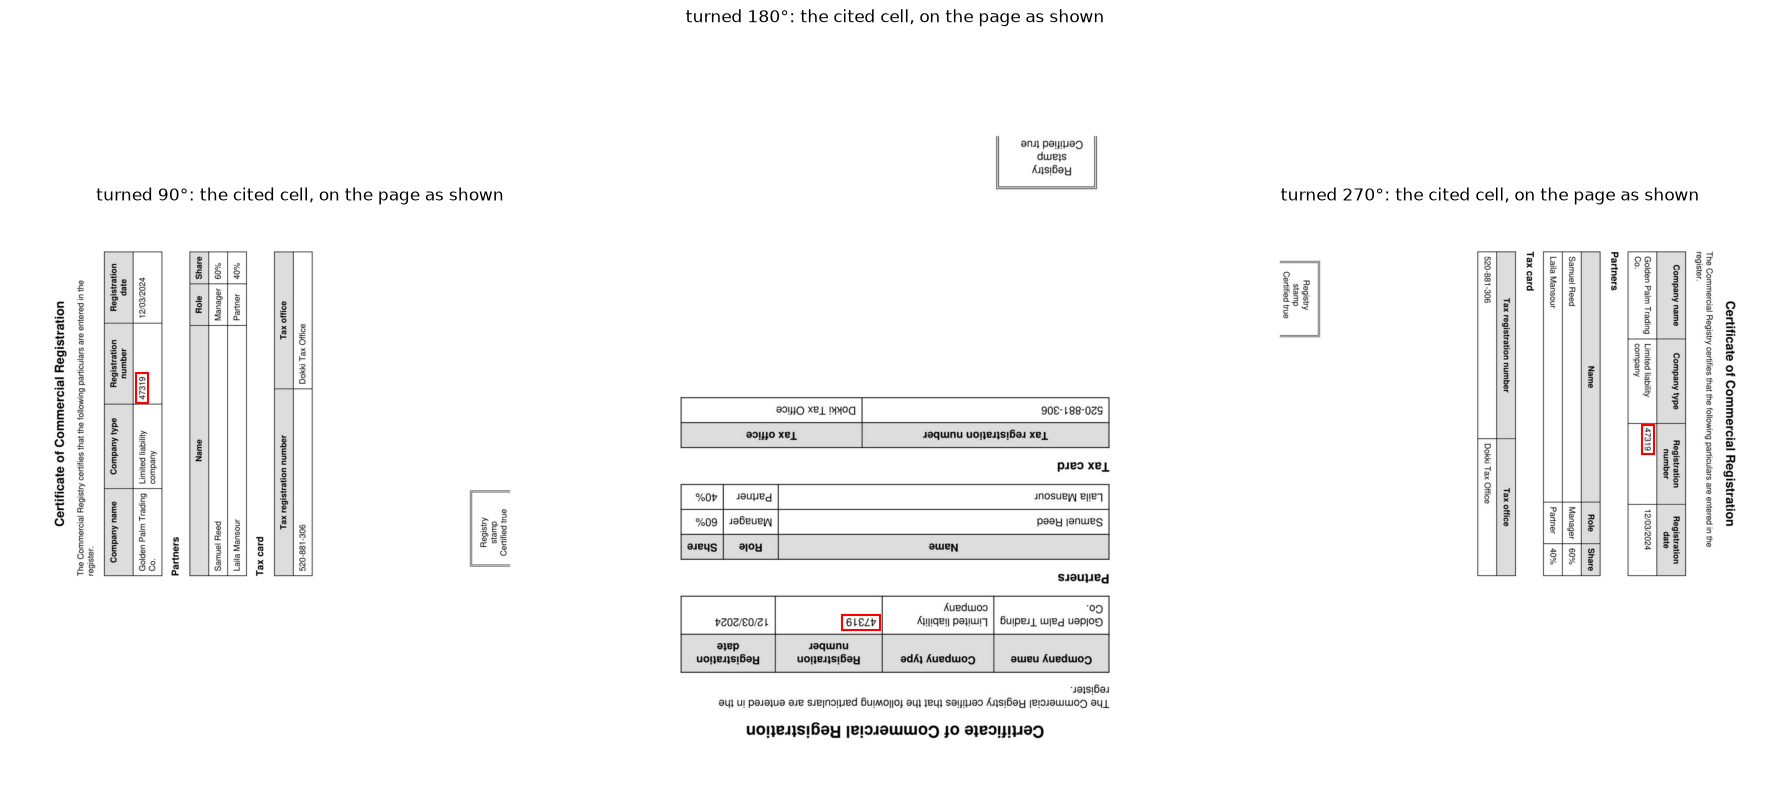

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (turn, (pg, box)) in zip(axes, cited.items()):
    ow, oh = original_size(pg.rotation, pg.width, pg.height)
    shown = pymupdf.open(turned[turn])[0]
    zoom = ow / shown.rect.width
    p = shown.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
    ax.imshow(Image.frombytes('RGB', (p.width, p.height), p.samples))
    x0, y0, x1, y1 = to_original(box, pg.rotation, pg.width, pg.height)
    pad = 12
    ax.add_patch(patches.Rectangle((x0 - pad, y0 - pad), x1 - x0 + 2 * pad, y1 - y0 + 2 * pad,
                                   fill=False, edgecolor='red', linewidth=1.5))
    ax.set_title(f'turned {turn}°: the cited cell, on the page as shown'); ax.axis('off')
plt.tight_layout(); plt.show()

On each turned page the answer comes from Docling's table cell, and the cited box (red) sits on the value on
the page as the file shows it.

## 10 · Where this leaves Inklight on real documents (measured, not shown here)

The fixes above were measured on the evaluation's real workload: 38 tasks on 25 documents, mostly scanned
Egyptian commercial registers, tax cards and VAT certificates (private, so not in this notebook). An AI user agent
did each task through the command line with up to four actions; blinded AI judges graded the evaluated build
(`3f1ec75`) and the corrected one together. The numbers below are read from the public ledger
(`bench/results/agent_eval/amendment-1/ledger-v2.jsonl`).

In [24]:
ledger = pd.read_json(ROOT / 'bench' / 'results' / 'agent_eval' / 'amendment-1' / 'ledger-v2.jsonl', lines=True)
scored = ledger[ledger['scored']]
names = {'A': 'evaluated build, structure off', 'A2': 'corrected build, structure off',
         'B': 'evaluated build, structure on', 'B2': 'corrected build, structure on'}
table = pd.DataFrame({
    names[arm]: {
        'tasks': len(g),
        'completed by the tool': int(g['tool_completed'].sum()),
        'correct only because the person read the page': int(g['manual_rescue'].sum()),
        'first answer correct': int((g['first_attempt'] == 'correct').sum()),
        'first answer wrong or failed': int(g['first_attempt'].isin(['wrong', 'failed']).sum()),
        'first answer abstained': int((g['first_attempt'] == 'abstained').sum()),
    }
    for arm, g in scored.groupby('arm')
})
table[[names[a] for a in ('A', 'A2', 'B', 'B2')]]

,"evaluated build, structure off","corrected build, structure off","evaluated build, structure on","corrected build, structure on"
tasks,38,38,38,38
completed by the tool,1,1,0,0
correct only because the person read the page,36,35,37,37
first answer correct,0,0,0,0
first answer wrong or failed,21,20,22,21
first answer abstained,10,10,7,6


**The honest reading.** The fixes made failures safer (no field name presented as a value on the control, no
silently chosen company, no false "two documents" error) and gave turned pages structure, but **task completion
did not improve**: the tool completed one task in 38 at best (a correct "not in the document"); every other
correct result needed the person to read the page. Most values were lost after OCR, when choosing the answer;
OCR itself lost about a quarter. Details, the stage diagnosis and what remains: `docs/AGENT_EVALUATION.md`.

## Summary

* Indra is the only OCR. Docling's layout, reading order and TableFormer run on Indra's stored lines: every line is
  handed over, no foreign words come back, and the marker control shows no second OCR.
* On these synthetic cards, answers to "what is the X" come from the cell under the heading, not the heading, and
  from the row of the person asked about; each answer cites the cell's page and box. The 11 of 11 in section 5 is
  11 questions chosen for three synthetic cards made for this showcase, not a measure of accuracy on real documents.
* OCR misreads are not hidden: answers built on low-confidence cells are flagged.
* Speed: the defaults (ONNX layout, all cores, models loaded during OCR) keep every answer; the faster options
  cost answers and stay off. Details and the full comparison: `docs/STRUCTURE.md`.
* Since the agent-run evaluation: a numbered form field name, or a run of field names merged into one block, is
  declined instead of returned as a value in the reproduced cases (the answer points at the field); other layouts
  may still slip through, several matching tables or documents are listed rather than the first taken, the documents you pass
  are kept, and turned pages get structure with citations placed on the page as shown.
* On the evaluation's real scanned registers, tax cards and VAT certificates this did **not** raise task completion
  (one task in 38 at best). Inklight is not suited to unattended work on such documents.